# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [21]:
ПІБ = 'Ільящук Марта Тарасівна'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-31'      # напр. 'КН-31'
ВАРІАНТ = 7    # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [22]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 7 · Ільящук Марта Тарасівна, ШІ-31, «Карпатський дуб»
Підприємство «Карпатський дуб» виготовляє меблі. Одиниця виміру плану: шт./тиждень.

                   Крісло  Стілець  Табурет  Лава  ЗАПАС
Дубовий брус, м         0        0        5     5   1189
Фанера, м²              4        4        0     1   1189
Фурнітура, компл.       2        4        0     6   1217
Верстат, год            6        3        4     1    915
Лакування, год          2        2        1     0    424

                    Крісло  Стілець  Табурет  Лава
Прибуток з одиниці      20       59       63    41

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Верстат, год
  ціна:   8.0 за одиницю
  обсяг:  до 314 одиниць


In [23]:

import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель**

Змінні рішення: <br>
                x1 - к-сть крісел (шт/тиждень),<br>
                x2 - к-сть стільців (шт/тиждень),<br>
                x3 - к-сть табуретів (шт/тиждень),<br>
                x4 - к-сть лав (шт/тиждень)<br>

Цільова функція: Z = 20*x1 + 59*x2 + 63*x3 + 41*x4 -> max

Обмеження:  <br>
            0*x1 + 0*x2 + 5*x3 + 5*x4 <= 1189<br>
            4*x1 + 4*x2 + 0*x3 + 1*x4 <= 1189<br>
            2*x1 + 4*x2 + 0*x3 + 6*x4 <= 1217<br>
            6*x1 + 3*x2 + 4*x3 + 1*x4 <= 915<br>
            2*x1 + 2*x2 + 1*x3 + 0*x4 <= 424<br>

Невід'ємність: x1, x2, x3, x4 >= 0


### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:**
Запас ресурсу - параметр, тому що його значення відоме заздалегідь і задане зовнішніми умовами або початковим станом підприємства на плановий період.<br>
Якби підприємство могло докупити ресурс у будь-якій кількості:<br>
1. Запас ресурсу став би змінною рішення: Обсяг додатково закупленого ресурсу y перетворився б на шукану змінну.<br>
2. Змінилася б цільова функція: З максимізації чистого прибутку від випуску потрібно було б віднімати витрати на купівлю ресурсу (ціна y).<br>
3. Змінилися б обмеження: Права частина обмеження збільшилася б на величину закупленого ресурсу.<br>
4. Зникла б проблема дефіцитності: Обмеження за цим ресурсом перестало б бути жорстким лімітом, а модель сама визначала б оптимум: докуповувати ресурс доти, доки граничний прибуток від випуску продукції перевищує вартість його закупівлі.<br>

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [24]:
# впишіть числа, які дав Excel
EXCEL_ПЛАН    = [0, 114.46, 111.27333333, 126.52666667]     # оптимальний випуск кожного виробу
EXCEL_ПРИБУТОК = 18950.95333         # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)

Excel: [0, 114.46, 111.27333333, 126.52666667] | прибуток 18950.95333


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [25]:
# ВАШ КОД

план = None
прибуток = None
import numpy as np
from scipy.optimize import linprog

c = [-20, -59, -63, -41]

A = [
    [0, 0, 5, 5], 
    [4, 4, 0, 1],  
    [2, 4, 0, 6],  
    [6, 3, 4, 1], 
    [2, 2, 1, 0],  
]

b = [1189, 1189, 1217, 915, 424]


x_bounds = [(0, None), (0, None), (0, None), (0, None)]


res = linprog(c, A_ub=A, b_ub=b, bounds=x_bounds, method="highs")


план = list(res.x)
прибуток = -res.fun

print(f"Оптимальний план: {план}")
print(f"Максимальний прибуток: {прибуток}")


Оптимальний план: [np.float64(0.0), np.float64(114.46), np.float64(111.27333333333334), np.float64(126.5266666666667)]
Максимальний прибуток: 18950.953333333335


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [26]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Дубовий брус | 1189 | 0,81333333 | 1189 | 715,375 | 369,735294117647 |
| Фанера | 584,36666667 | 0 | 1189 | 1E+30 | 604,633333333334 |
| Фурнітура | 1217 | 3,7 | 1217 | 838,066666666667 | 1144,6 |
| Верстат | 915  | 14,73333333 | 915 | 157,1375 | 572,3 |
| Лакування | 340,19333333 | 0 | 424 | 1E+30 | 83,8066666666667 |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**<br>
Дефіцитні ресурси: дубовй брус, фурнітура, верстат.<br>
Надлишкові ресурси: фанера, лакування. <br>
Як визначили: 
- для ресурсів у дефіциті кінцеве значення = правій частині (ресурс вичерпано)
- для надлишкових ресурсів кінцеве значення < права частина (ресурс невичерпано)





### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Крісло | 0 | -75,8 | 20 | 75,8 | 1E+30 |
| Стілець | 114,46 | 0 | 59 | 5,08333333333333 | 37 |
| Табурет | 111,27333333 | 0 | 63 | 37 | 8,71428571428572 |
| Лава | 126,52666667 | 0 | 41 | 110,5 | 7,625 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?<br>
Виріб який не виробляється: крісло.<br>
На скільки мусив би зрости прибуток: на 75,8.<br>
Число взяте зі зведеної вартості/допустимого збільшення.


---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [27]:
# ВАШ КОД

c_arr = np.array(V['c'], dtype=float)
b_arr = np.array(V['b'], dtype=float)
A_arr = np.array(V['A'], dtype=float)


res_base = linprog(-c_arr, A_ub=A_arr, b_ub=b_arr, bounds=(0, None), method='highs')
прибуток_базовий = -res_base.fun

i_max = 3 

b_exp = b_arr.copy()
b_exp[i_max] += 1

res_exp = linprog(-c_arr, A_ub=A_arr, b_ub=b_exp, bounds=(0, None), method='highs')
прибуток_новий = -res_exp.fun

приріст = прибуток_новий - прибуток_базовий
тіньова_ціна_зі_звіту = 14.733333333333333

print(f"Ресурс з найвищою тіньовою ціною: {ресурси[i_max]}")
print(f"Базовий прибуток:            {прибуток_базовий:.4f} грн")
print(f"Прибуток після додавання +1: {прибуток_новий:.4f} грн")
print(f"Фактичний приріст прибутку:  {приріст:.4f} грн")
print(f"Тіньова ціна зі звіту:       {тіньова_ціна_зі_звіту:.4f} грн")

Ресурс з найвищою тіньовою ціною: Верстат, год
Базовий прибуток:            18950.9533 грн
Прибуток після додавання +1: 18965.6867 грн
Фактичний приріст прибутку:  14.7333 грн
Тіньова ціна зі звіту:       14.7333 грн


**Відповідь 5.1:** *(приріст прибутку =  14.7333 грн, тіньова ціна зі звіту = 14.7333 грн, збігаються?)*

### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

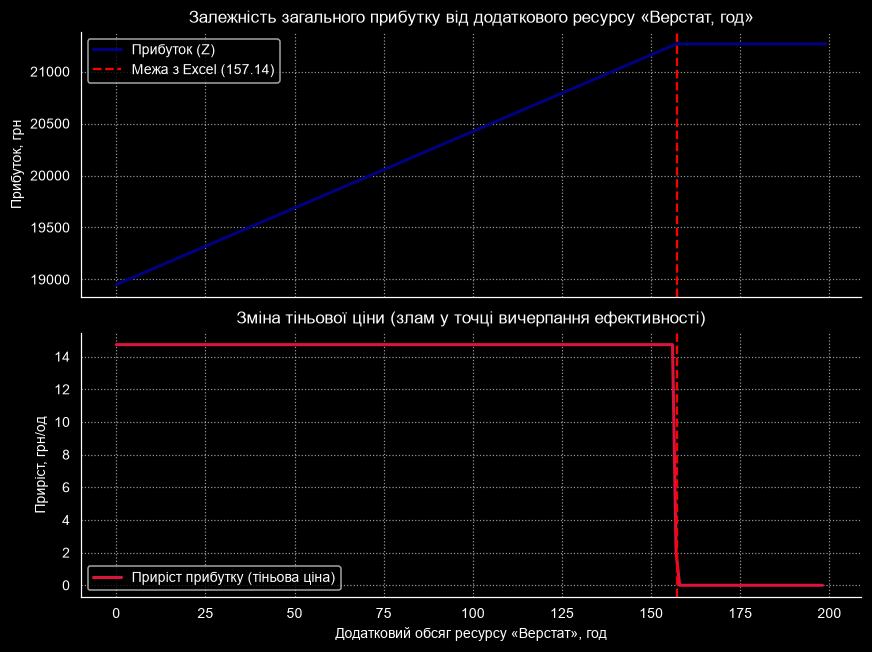

In [28]:
# ВАШ КОД

c_arr = np.array(V['c'], dtype=float)
b_arr = np.array(V['b'], dtype=float)
A_arr = np.array(V['A'], dtype=float)

i_max = 3  
deltas = np.arange(0, 200, 1)  

profits = []
for d in deltas:
    b_temp = b_arr.copy()
    b_temp[i_max] += d
    res = linprog(-c_arr, A_ub=A_arr, b_ub=b_temp, bounds=(0, None), method='highs')
    profits.append(-res.fun)

profits = np.array(profits)
slopes = np.diff(profits)  

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

ax1.plot(deltas, profits, color='navy', lw=2, label='Прибуток (Z)')
ax1.axvline(x=157.1375, color='red', linestyle='--', label='Межа з Excel (157.14)')
ax1.set_ylabel('Прибуток, грн')
ax1.set_title('Залежність загального прибутку від додаткового ресурсу «Верстат, год»')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.plot(deltas[:-1], slopes, color='crimson', lw=2, label='Приріст прибутку (тіньова ціна)')
ax2.axvline(x=157.1375, color='red', linestyle='--')
ax2.set_xlabel('Додатковий обсяг ресурсу «Верстат», год')
ax2.set_ylabel('Приріст, грн/од')
ax2.set_title('Зміна тіньової ціни (злам у точці вичерпання ефективності)')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

shadow_price = 14.733333333333333
break_delta = np.where(np.abs(slopes - shadow_price) > 1e-3)[0][0]

**Відповідь 5.2:** *(на скільки одиниць можна збільшити запас, доки тіньова ціна не зміниться;
чи збігається знайдена межа з «допустимим збільшенням» зі звіту Excel)*
Тіньова ціна зберігається сталою (+14.73 грн) до додаткових 157 одиниць.

---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [29]:
# ВАШ КОД

c_arr = np.array(V['c'], dtype=float)
b_arr = np.array(V['b'], dtype=float)
A_arr = np.array(V['A'], dtype=float)

res_base = linprog(-c_arr, A_ub=A_arr, b_ub=b_arr, bounds=(0, None), method='highs')
прибуток_базовий = -res_base.fun

i_res = V['ресурс_пропозиції']         
ціна_пропозиції = V['ціна_пропозиції']  
обсяг_пропозиції = V['обсяг_пропозиції'] 

тіньова_ціна = 14.733333333333333      
допустиме_збільшення = 157.1375        


обсяг_закупівлі = min(обсяг_пропозиції, допустиме_збільшення)

b_новий = b_arr.copy()
b_новий[i_res] += обсяг_закупівлі

res_новий = linprog(-c_arr, A_ub=A_arr, b_ub=b_новий, bounds=(0, None), method='highs')
прибуток_новий = -res_новий.fun

валовий_виграш = прибуток_новий - прибуток_базовий
витрати_на_закупівлю = обсяг_закупівлі * ціна_пропозиції
чистий_виграш = валовий_виграш - витрати_на_закупівлю

print(f"Ресурс:                      {V['ресурси'][i_res]}")
print(f"Тіньова ціна ресурсу:        {тіньова_ціна:.4f} грн/год")
print(f"Ціна пропозиції:             {ціна_пропозиції:.2f} грн/год")
print(f"Оптимальний обсяг закупівлі: {обсяг_закупівлі:.4f} год (із запропонованих {обсяг_пропозиції} год)")
print(f"Базовий прибуток:            {прибуток_базовий:.2f} грн")
print(f"Новий валовий прибуток:      {прибуток_новий:.2f} грн")
print(f"Приріст валового прибутку:   {валовий_виграш:.2f} грн")
print(f"Витрати на закупівлю:        {витрати_на_закупівлю:.2f} грн")
print(f"Чистий прибуток:             {чистий_виграш:.2f} грн")


Ресурс:                      Верстат, год
Тіньова ціна ресурсу:        14.7333 грн/год
Ціна пропозиції:             8.00 грн/год
Оптимальний обсяг закупівлі: 157.1375 год (із запропонованих 314 год)
Базовий прибуток:            18950.95 грн
Новий валовий прибуток:      21266.11 грн
Приріст валового прибутку:   2315.16 грн
Витрати на закупівлю:        1257.10 грн
Чистий прибуток:             1058.06 грн


**Відповідь 6.1:**

* Брати чи ні і чому: тіньова ціна ресурсу «Верстат, год» становить **14,73 грн/год**, а постачальник пропонує його за **8,0 грн/од.**. Оскільки цінність кожної додаткової години для підприємства (14,73 грн) вища за ціну її придбання (8,0 грн), купівля є вигідною
* Скільки одиниць має сенс купити і чому не більше: купувати слід точно **157,14 одиниць** (або 157 год у цілих числах), а **не всі 314**, що пропонує постачальник. За звітом про стійкість межа «Допустимого збільшення» становить 157,1375 год. Понад цю межу тіньова ціна ресурсу стрімко падає нижче за 8,0 грн.
* Очікуваний виграш: 1058.06 грн (чистий прибуток)
* Перевірка прямим розв'язанням дала: 21266.11 грн 


---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [30]:
# ВАШ КОД
ненульових = int(np.sum(res_base.x > 1e-6))
звязних = int(np.sum(np.abs(res_base.slack) < 1e-6))


In [31]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 3 | зв’язних обмежень: 3
Етап 7 пройдено


**Відповідь 7.1:** *(чи збіглися числа; що означала б розбіжність на практиці)*
Так, числа збіглися. Кількість ненульових продуктів у плані випуску дорівнює **3** ($x_2 = 114.46$, $x_3 = 111.27$, $x_4 = 126.53$), і кількість зв'язних (повністю використаних) ресурсів також дорівнює **3** (Фурнітура, Верстат, а також перше обмеження).
* **Що означала б розбіжність на практиці:** 
  1. **Якщо ненульових > зв'язних:** Це вказує на помилку в розрахунках або порушення умов базису.
  2. **Якщо ненульових < зв'язних:** На практиці це означає, що підприємство повністю вичерпало декілька ресурсів, але один із видів продукції випускається в обсязі 0 одиниць (або певний ресурс був обмеженням для виробу, який не увійшов до плану).

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [32]:
# ВАШ КОД


res_cont = linprog(-c_arr, A_ub=A_arr, b_ub=b_arr, bounds=(0, None), method='highs')
x_cont = res_cont.x
p_cont = -res_cont.fun

x_round = np.round(x_cont)
p_round = np.dot(c_arr, x_round)
is_feasible_round = np.all(A_arr @ x_round <= b_arr)

res_int = linprog(-c_arr, A_ub=A_arr, b_ub=b_arr, bounds=(0, None), integrality=1, method='highs')
x_int = res_int.x
p_int = -res_int.fun
is_feasible_int = np.all(A_arr @ x_int <= b_arr)

print(f"1. Без цілочисельності: x = {np.round(x_cont, 2)}, Прибуток = {p_cont:.2f}, Допустимий = True")
print(f"2. Округлений:          x = {x_round.astype(int)}, Прибуток = {p_round:.2f}, Допустимий = {is_feasible_round}")
print(f"3. Цілочисельний:       x = {x_int.astype(int)}, Прибуток = {p_int:.2f}, Допустимий = {is_feasible_int}")

1. Без цілочисельності: x = [  0.   114.46 111.27 126.53], Прибуток = 18950.95, Допустимий = True
2. Округлений:          x = [  0 114 111 127], Прибуток = 18926.00, Допустимий = False
3. Цілочисельний:       x = [  0 115 111 126], Прибуток = 18944.00, Допустимий = True


**Відповідь 8.1:**

| Варіант | План | Прибуток | Допустимий? |
|---|---|---|---|
| без умови цілочисельності | 0.,   114.46, 111.27, 126.53  | 18950.95 | так |
| округлений |  0, 114, 111, 127 | 18926.00 | ні |
| цілочисельний оптимум |  0, 115, 111, 126 | 18944.00 | так |

**Висновок:** *(чи можна округлювати і чому)*
Ні, оскільки округлення призводить до порушення обмежень за ресурсами.


---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [33]:
# ВАШ КОД — впишіть свої дані

постачальники = ['Ізюм', 'Львів', 'Яремче']

споживачі = ['Миколаїв', 'Авдіївка', 'Рівне', 'Тернопіль']

D = np.array([
    [650,  160, 820, 860],  
    [800, 1200, 210, 130],  
    [750, 1180, 340, 210]   
])

запас = [100, 120, 80]

попит = [70, 80, 90, 60]

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'

pd.DataFrame(D, index=постачальники, columns=споживачі)

,Миколаїв,Авдіївка,Рівне,Тернопіль
Ізюм,650,160,820,860
Львів,800,1200,210,130
Яремче,750,1180,340,210


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [34]:
# ВАШ КОД — розв'язок 1

m, n = len(постачальники), len(споживачі)
model = pulp.LpProblem("Transportation_Problem", pulp.LpMinimize)

x = [[pulp.LpVariable(f"x_{i}_{j}", lowBound=0) for j in range(n)] for i in range(m)]

model += pulp.lpSum(x[i][j] * D[i][j] for i in range(m) for j in range(n))

for i in range(m):
    model += pulp.lpSum(x[i][j] for j in range(n)) == запас[i]

for j in range(n):
    model += pulp.lpSum(x[i][j] for i in range(m)) == попит[j]

model.solve(pulp.PULP_CBC_CMD(msg=False))

X_pulp = np.zeros((m, n))
for i in range(m):
    for j in range(n):
        X_pulp[i, j] = x[i][j].varValue

cost_pulp = pulp.value(model.objective)
shadow_pulp = [con.pi for con in model.constraints.values()]
print(f"Сумарна вартість перевезень: {cost_pulp:.2f} грн\n")
print("Оптимальний план перевезень:")
display(pd.DataFrame(np.round(X_pulp, 2), index=постачальники, columns=споживачі))

print("\nТіньові ціни обмежень:")
for name, price in zip(постачальники + споживачі, shadow_pulp):
    print(f" - {name}: {price:.2f}")

Сумарна вартість перевезень: 92400.00 грн

Оптимальний план перевезень:


,Миколаїв,Авдіївка,Рівне,Тернопіль
Ізюм,20.0,80.0,0.0,0.0
Львів,0.0,0.0,90.0,30.0
Яремче,50.0,0.0,0.0,30.0



Тіньові ціни обмежень:
 - Ізюм: 110.00
 - Львів: 130.00
 - Яремче: 210.00
 - Миколаїв: 540.00
 - Авдіївка: 50.00
 - Рівне: 80.00
 - Тернопіль: 0.00


In [35]:
# ВАШ КОД — розв'язок 2
c_vec = np.array(D).flatten()

A_supply = np.zeros((m, m * n))
for i in range(m):
    A_supply[i, i*n:(i+1)*n] = 1

A_demand = np.zeros((n, m * n))
for j in range(n):
    A_demand[j, j::n] = 1

A_eq = np.vstack([A_supply, A_demand])
b_eq = np.concatenate([запас, попит])

res = linprog(c_vec, A_eq=A_eq, b_eq=b_eq, bounds=(0, None), method='highs')

X_scipy = res.x.reshape((m, n))
cost_scipy = res.fun
shadow_scipy = res.eqlin.marginals

print(f"Сумарна вартість перевезень: {cost_scipy:.2f} грн\n")
print("Оптимальний план перевезень:")
display(pd.DataFrame(np.round(X_scipy, 2), index=постачальники, columns=споживачі))

print("\nТіньові ціни обмежень:")
for name, price in zip(постачальники + споживачі, shadow_scipy):
    print(f" - {name}: {price:.2f}")

Сумарна вартість перевезень: 92400.00 грн

Оптимальний план перевезень:


,Миколаїв,Авдіївка,Рівне,Тернопіль
Ізюм,20.0,80.0,0.0,0.0
Львів,0.0,0.0,90.0,30.0
Яремче,50.0,0.0,0.0,30.0



Тіньові ціни обмежень:
 - Ізюм: -0.00
 - Львів: 20.00
 - Яремче: 100.00
 - Миколаїв: 650.00
 - Авдіївка: 160.00
 - Рівне: 190.00
 - Тернопіль: 110.00


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [36]:
# ВАШ КОД — порівняння
df_comparison = pd.DataFrame({
    'SciPy (linprog)': shadow_scipy,
    'PuLP (CBC)': shadow_pulp,
}, index=постачальники + споживачі)

df_comparison['Різниця (PuLP - SciPy)'] = df_comparison['PuLP (CBC)'] - df_comparison['SciPy (linprog)']

display(df_comparison)
diff_suppliers = df_comparison.loc[постачальники, 'Різниця (PuLP - SciPy)'].values
diff_consumers = df_comparison.loc[споживачі, 'Різниця (PuLP - SciPy)'].values

print(f"\nЗсув для постачальників: {diff_suppliers[0]:.2f}")
print(f"Зсув для споживачів:    {diff_consumers[0]:.2f}")

,SciPy (linprog),PuLP (CBC),Різниця (PuLP - SciPy)
Ізюм,-0.0,110.0,110.0
Львів,20.0,130.0,110.0
Яремче,100.0,210.0,110.0
Миколаїв,650.0,540.0,-110.0
Авдіївка,160.0,50.0,-110.0
Рівне,190.0,80.0,-110.0
Тернопіль,110.0,0.0,-110.0



Зсув для постачальників: 110.00
Зсув для споживачів:    -110.00


**Відповідь 10.2:**

* Вартість у двох розв'язувачів: однакова — 92 400.00 грн
* Тіньові ціни збіглися чи ні: ні.
* Яку закономірність ви побачили в різниці: для всіх постачальників оцінки PuLP більші за оцінки SciPy рівно на +110.00. Для всіх споживачів оцінки PuLP менші за оцінки SciPy рівно на -110.00.
* Що це означає для того, хто збирається ухвалювати рішення за цим звітом:
обидва звіти є математично еквівалентними та однаково правильними. Для прийняття управлінських рішень важливо аналізувати відносні різниці між пунктами (наприклад, оцінка Львів дешевша за Яремче на 80 грн/т в обох розв'язувачах), а не абсолютні значення тіньових цін окремих пунктів.


---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [37]:
# ВАШ КОД

eps = 1e-5
non_zero_shipments = np.sum(X_scipy > eps)


binding_constraints = len(shadow_scipy)  

total_constraints = m + n

print(f"Кількість ненульових перевезень: {non_zero_shipments}")
print(f"Кількість зв'язаних обмежень:    {binding_constraints}")
print(f"Загальна кількість обмежень (m + n): {total_constraints}")

Кількість ненульових перевезень: 6
Кількість зв'язаних обмежень:    7
Загальна кількість обмежень (m + n): 7


**Відповідь 11.1:**

* Ненульових перевезень: 6
* Зв'язних обмежень: 7
* Чому в транспортній задачі зв'язними виявляються **всі** обмеження: оскільки задача є закритою (збалансованою) — загальний запас ($130 + 90 + 80 = 300$) точно дорівнює загальному попиту ($70 + 80 + 90 + 60 = 300$), усі обмеження записані як суворі рівняння ($=$). Це означає, що всі запаси вивозяться повністю, а всі потреби задовольняються на 100%, тому всі 7 обмежень є активними (зв'язаними).
* На скільки ненульових перевезень менше і чому саме на стільки: ненульових перевезень менше на 1 (6 замість 7). У транспортній задачі одне з обмежень є лінійно залежним від інших (сума всіх запасів тотожно дорівнює сумі всіх потреб).


### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

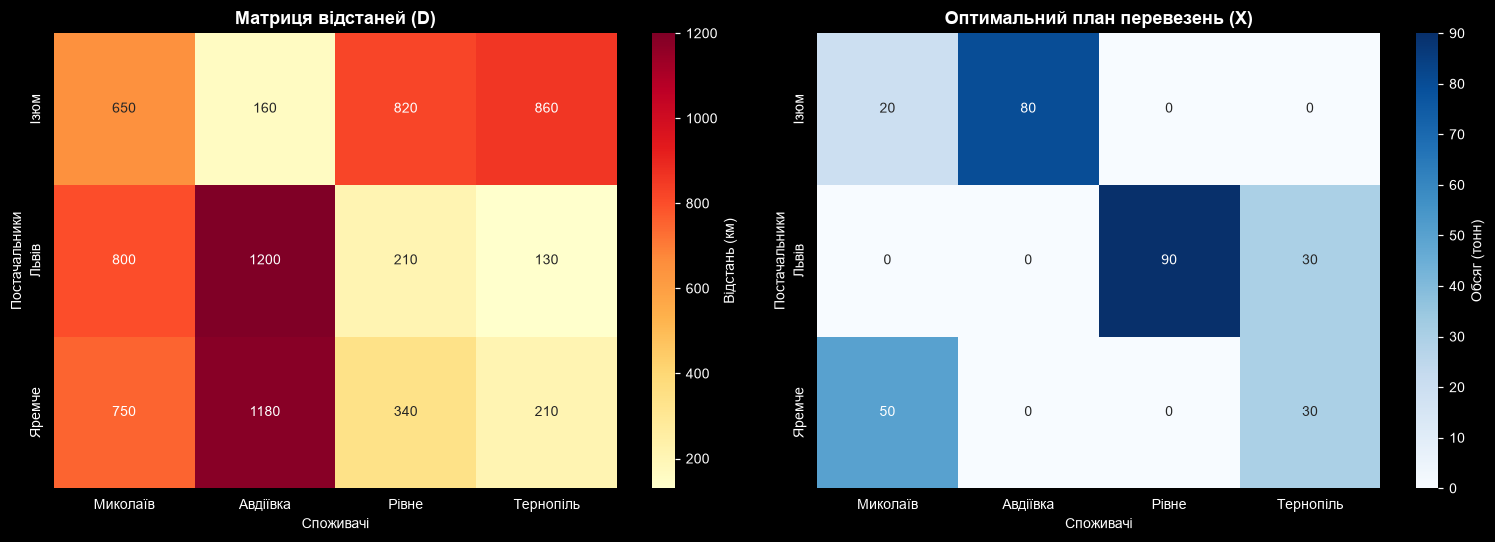

In [38]:
# ВАШ КОД
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    D, 
    annot=True, 
    fmt=".0f", 
    cmap="YlOrRd", 
    xticklabels=споживачі, 
    yticklabels=постачальники, 
    ax=axes[0],
    cbar_kws={'label': 'Відстань (км)'}
)
axes[0].set_title("Матриця відстаней (D)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Споживачі")
axes[0].set_ylabel("Постачальники")

sns.heatmap(
    X_scipy, 
    annot=True, 
    fmt=".0f", 
    cmap="Blues", 
    xticklabels=споживачі, 
    yticklabels=постачальники, 
    ax=axes[1],
    cbar_kws={'label': 'Обсяг (тонн)'}
)
axes[1].set_title("Оптимальний план перевезень (X)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Споживачі")
axes[1].set_ylabel("Постачальники")

plt.tight_layout()
plt.show()

**Висновок:** *(одне речення про те, що видно на теплових картах)*<br>
Теплові карти наочно демонструють, що модель повністю уникає маршрутів із найбільшими відстанями (наприклад, Ізюм–Тернопіль чи Львів–Миколаїв) і спрямовує основні обсяги перевезень між найбільш близько розташованими пунктами.

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [39]:
ІНСТРУМЕНТИ_ШІ = 'Gemini'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':          'ні',
    'етап 2, побудова моделі в Excel':      'ні',
    'етап 3, код на Python':                'синтаксис',
    'етапи 4–5, читання та перевірка звіту': 'ні',
    'етап 6, рішення про закупівлю':        'текст, перероблено',
    'етапи 7–8, перевірка та цілочисельність': 'ні',
    'етапи 9–11, транспортна задача':       'синтаксис',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно.
ЩО_ПЕРЕВІРЕНО = "Перевірено правильність виклику методів SciPy (linprog) та PuLP (LpProblem), формування матриці обмежень A_eq, відповідність оптимальних планів перевезень sу двох розв'язувачах, а також математичне обґрунтування зсуву тіньових цін (C = 110)."

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [40]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Ільящук Марта Тарасівна
інструменти:                               Gemini
------------------------------------------------------------------------------
етап 1, формалізація моделі:               ні
етап 2, побудова моделі в Excel:           ні
етап 3, код на Python:                     синтаксис
етапи 4–5, читання та перевірка звіту:     ні
етап 6, рішення про закупівлю:             текст, перероблено
етапи 7–8, перевірка та цілочисельність:   ні
етапи 9–11, транспортна задача:            синтаксис
------------------------------------------------------------------------------
Перевірено правильність виклику методів SciPy (linprog) та PuLP (LpProblem), формування матриці обмежень A_eq, відповідність оптимальних планів перевезень sу двох розв'язувачах, а також математичне обґрунтування зсуву тіньових цін (C = 110).


---
# Крок 13. Фінальна самоперевірка

In [41]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
